<!-- gs-watermark -->
> **© 2026 Gokaran Shukla** · part of [hopforge](https://github.com/Gokaran-Shukla/hopforge) · MIT License — any reuse must keep this copyright notice and credit the author.

# 21 · Allan MacDonald's models: moiré TMDs, rhombohedral graphene, spin Hall and QAH

`hf.macdonald` collects the Hamiltonians of A. H. MacDonald's group (UT Austin). The group has not
released a general tight-binding package: its models live in the papers, so hopforge implements them
and checks each one against the published numbers (`python -m hopforge.benchmarks`).

| Object | Paper | What it shows |
|---|---|---|
| `BistritzerMacDonald` | PNAS 108, 12233 (2011) | magic-angle flat bands in TBG (tutorial 20) |
| `TMDHeterobilayer` | Wu, Lovorn, Tutuc & MacDonald, PRL 121, 026402 (2018) | flat moiré bands → triangular Hubbard model |
| `TMDHomobilayer` | Wu, Lovorn, Tutuc, Martin & MacDonald, PRL 122, 086402 (2019) | topological moiré bands, Kane-Mele physics |
| `rhombohedral_graphene` | Min & MacDonald, PRB 77, 155416 (2008) | chiral decomposition, $E\propto k^N$, valley Chern $N/2$ |
| `rashba_2deg` + `sinova_spin_hall` | Sinova et al., PRL 92, 126603 (2004) | universal spin Hall conductivity $e/8\pi$ |
| `graphene_qah` | Tse, Qiao, Yao, MacDonald & Niu, PRB 83, 155447 (2011) | quantum anomalous Hall with $C=2$ |

Continuum models use **nm and meV**; holes are described by $-\hbar^2k^2/2m^*$ (valence bands),
and bands are sorted from the top down.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import hopforge as hf
M = hf.models
%matplotlib inline
MD = hf.macdonald

## 1 · TMD heterobilayer: a Hubbard model you can tune with the twist angle

$$H=-\frac{\hbar^2k^2}{2m^*}+\Delta(\mathbf r),\qquad \Delta(\mathbf r)=\sum_{j=1}^{6}V(\mathbf b_j)e^{i\mathbf b_j\cdot\mathbf r},\quad V(\mathbf b_1)=Ve^{i\psi}.$$

WSe$_2$/MoSe$_2$: $(V,\psi)=(6.6\ \mathrm{meV},-94^\circ)$, $m^*=0.35m_e$, $a_M=a_0/\theta$.

top bandwidth: 10.85 meV  (paper: ~11 meV)


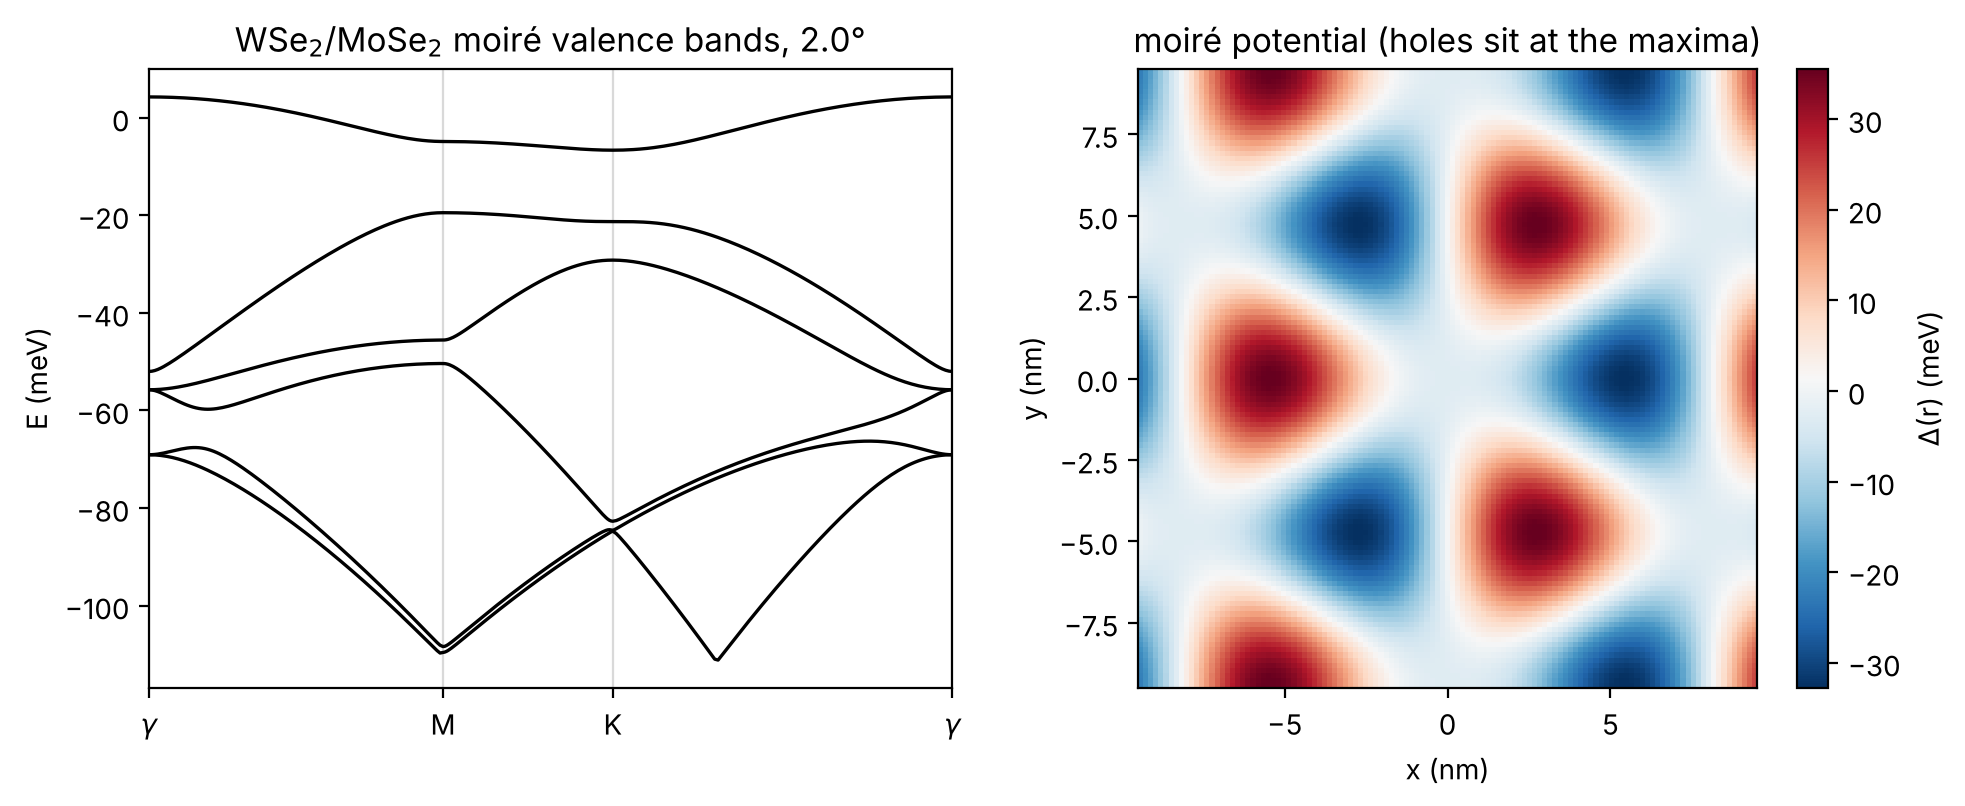

In [2]:
h = MD.TMDHeterobilayer(theta=2.0)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
h.plot_bands(path=("G", "M", "K", "G"), nbands=6, ax=ax[0])
ax[0].set_title("WSe$_2$/MoSe$_2$ moiré valence bands, 2.0°")
x = np.linspace(-1, 1, 121) * h.aM
X, Y = np.meshgrid(x, x)
D = h.potential(np.stack([X.ravel(), Y.ravel()], 1)).reshape(X.shape)
im = ax[1].imshow(D, extent=[x[0], x[-1], x[0], x[-1]], origin="lower", cmap="RdBu_r")
plt.colorbar(im, ax=ax[1], label="Δ(r) (meV)"); ax[1].set_title("moiré potential (holes sit at the maxima)")
ax[1].set_xlabel("x (nm)"); ax[1].set_ylabel("y (nm)")
plt.tight_layout()
print("top bandwidth:", round(h.bandwidths(1)[0], 2), "meV  (paper: ~11 meV)")

### Hubbard parameters
The top band is Fourier-transformed into triangular-lattice hoppings $t_1,t_2,t_3$. The on-site $U_0$ uses the harmonic-oscillator Wannier function around the potential maximum, $U_0=\sqrt{\pi/2}\,e^2/(\epsilon a_W)$. The fitted tight-binding band reproduces the continuum band.

{'t': [1.247, -0.177, -0.095], 'distances': [np.float64(1.0), np.float64(1.732), np.float64(2.0)], 'onsite': np.float64(-1.945), 'U0': np.float64(84.281), 'a_W': np.float64(2.141), 'hbar_omega': np.float64(47.481), 'aM': np.float64(9.511)}


Text(0.5, 1.0, 'Hubbard-model band vs continuum')

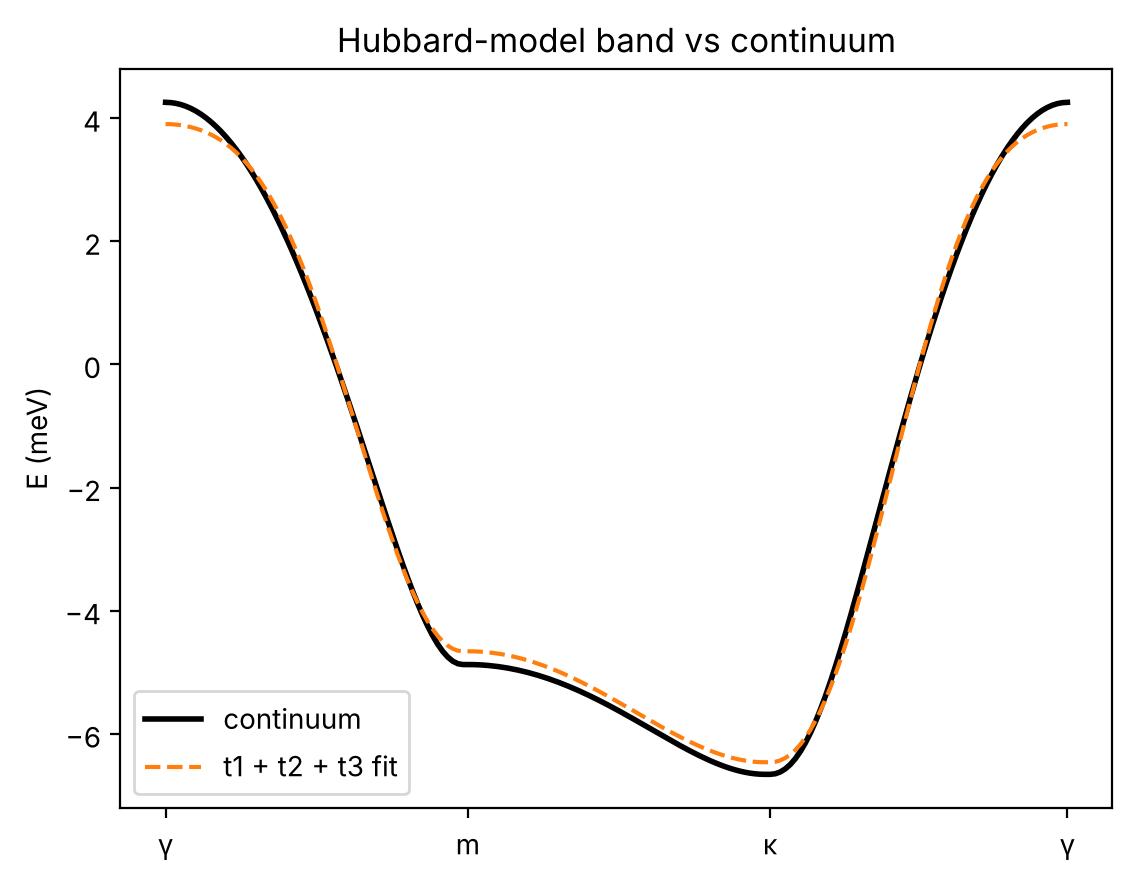

In [3]:
p = h.hubbard(eps=10.0)
print({k: (np.round(v, 3) if not isinstance(v, list) else [round(x, 3) for x in v]) for k, v in p.items()})
tb = h.to_model()
B = h.B
path = [np.zeros(2), 0.5 * B[0], (B[0] + B[1]) / 3, np.zeros(2)]
ks = np.concatenate([a + np.linspace(0, 1, 60)[:, None] * (b - a) for a, b in zip(path[:-1], path[1:])])
E_cont = h.energies(ks, 1)[:, 0]
kf = np.linalg.solve(tb.lat.reciprocal[:2, :2].T, ks.T).T
E_tb = tb.energies(kf)[:, 0]
plt.plot(E_cont, "k", lw=2, label="continuum"); plt.plot(E_tb, "--", color="tab:orange", label="t1 + t2 + t3 fit")
plt.ylabel("E (meV)"); plt.xticks([0, 60, 120, 179], ["γ", "m", "κ", "γ"]); plt.legend(); plt.title("Hubbard-model band vs continuum")

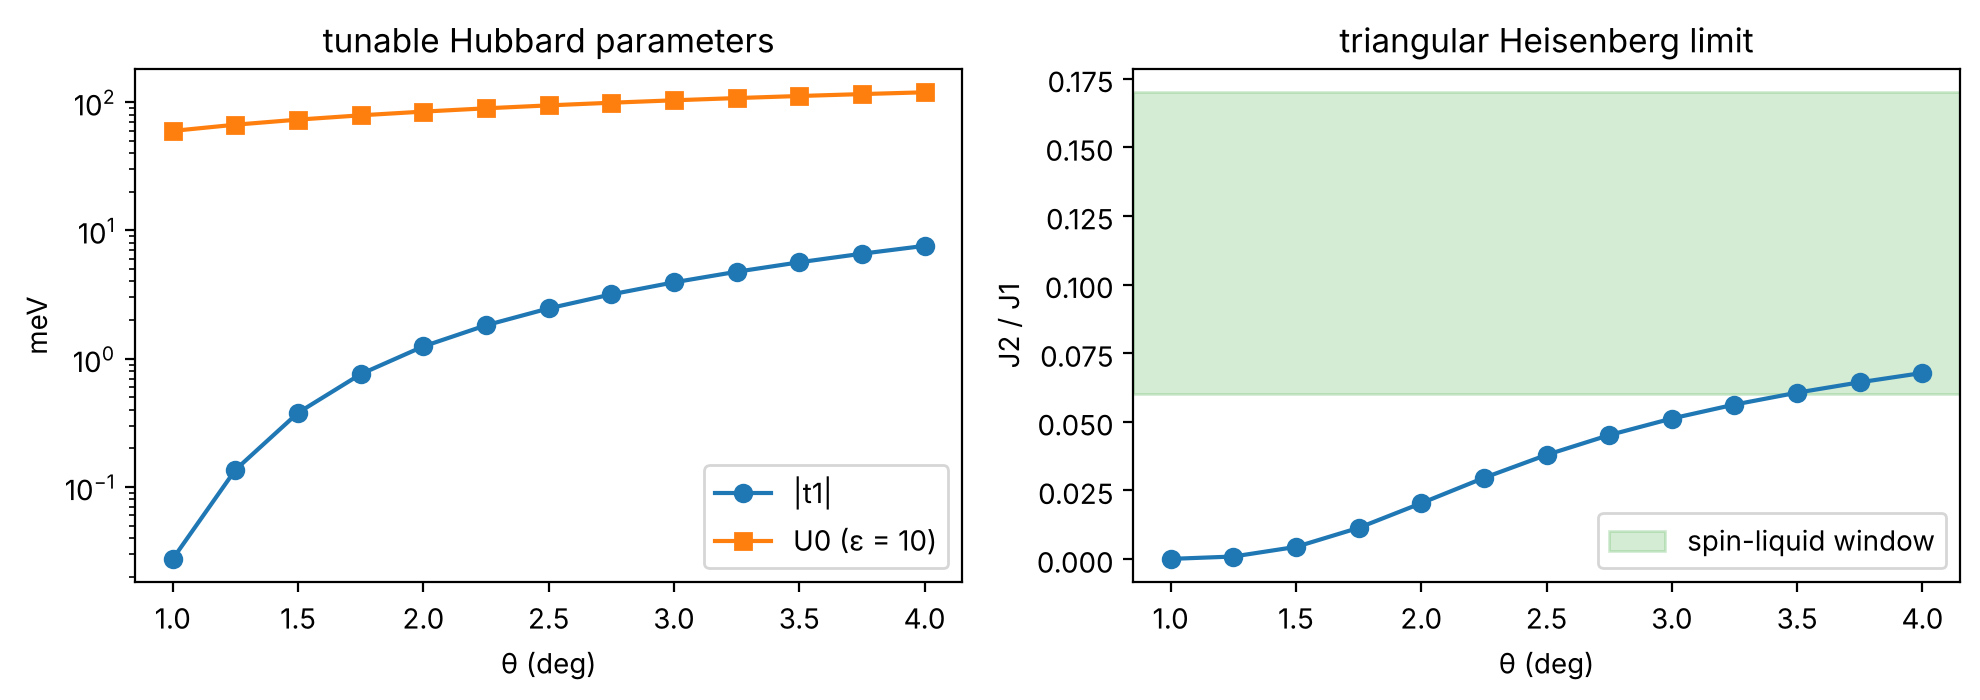

In [4]:
thetas = np.linspace(1.0, 4.0, 13)
rows = []
for th in thetas:
    q = MD.TMDHeterobilayer(theta=th).hubbard(eps=10.0)
    t1, t2 = q["t"][0], q["t"][1]
    J1 = 4 * t1**2 / q["U0"] * (1 - 7 * (t1 / q["U0"])**2)
    J2 = 4 * t2**2 / q["U0"] + 4 * t1**4 / q["U0"]**3
    rows.append((t1, q["U0"], J2 / J1))
rows = np.array(rows)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].semilogy(thetas, np.abs(rows[:, 0]), "o-", label="|t1|"); ax[0].semilogy(thetas, rows[:, 1], "s-", label="U0 (ε = 10)")
ax[0].set_xlabel("θ (deg)"); ax[0].set_ylabel("meV"); ax[0].legend(); ax[0].set_title("tunable Hubbard parameters")
ax[1].plot(thetas, rows[:, 2], "o-"); ax[1].axhspan(0.06, 0.17, color="tab:green", alpha=0.2, label="spin-liquid window")
ax[1].set_xlabel("θ (deg)"); ax[1].set_ylabel("J2 / J1"); ax[1].legend(); ax[1].set_title("triangular Heisenberg limit")
plt.tight_layout()

Smaller angles flatten the band exponentially, while $U_0$ falls only slowly. So $U/t$ grows rapidly as θ decreases: twist angle is a knob for correlation strength, and $J_2/J_1$ (spin-liquid window $0.06\lesssim J_2/J_1\lesssim0.17$) follows.

**Caveat:** $U_0$ here is the harmonic-oscillator estimate with bare $1/r$ Coulomb. Wu et al. project a gate-screened interaction ($D=3$ nm) onto Wannier functions, which gives a somewhat smaller $U_0$. Their $J_2/J_1$ therefore enters the window at θ ≈ 3.0°, earlier than in this plot. Trends are reliable; for quantitative $U$, compute Wannier functions with the screened interaction.

## 2 · Twisted MoTe$_2$: topological moiré bands

$$H_\uparrow=\begin{pmatrix}-\frac{\hbar^2(\mathbf k-\boldsymbol\kappa_+)^2}{2m^*}+\Delta_b & \Delta_T\\ \Delta_T^\dagger & -\frac{\hbar^2(\mathbf k-\boldsymbol\kappa_-)^2}{2m^*}+\Delta_t\end{pmatrix},\quad
\Delta_{b,t}=2V\sum_{j=1,3,5}\cos(\mathbf g_j\cdot\mathbf r\pm\psi),\quad \Delta_T=w(1+e^{-i\mathbf g_2\cdot\mathbf r}+e^{-i\mathbf g_3\cdot\mathbf r}).$$

$(V,\psi,w)=(8\ \mathrm{meV},-89.6^\circ,-8.5\ \mathrm{meV})$, $m^*=0.62m_e$. In the paper the top two bands have $C=(-1,+1)$ at 1.2°, and the third band takes part above $\theta_1^*\approx1.74^\circ$.

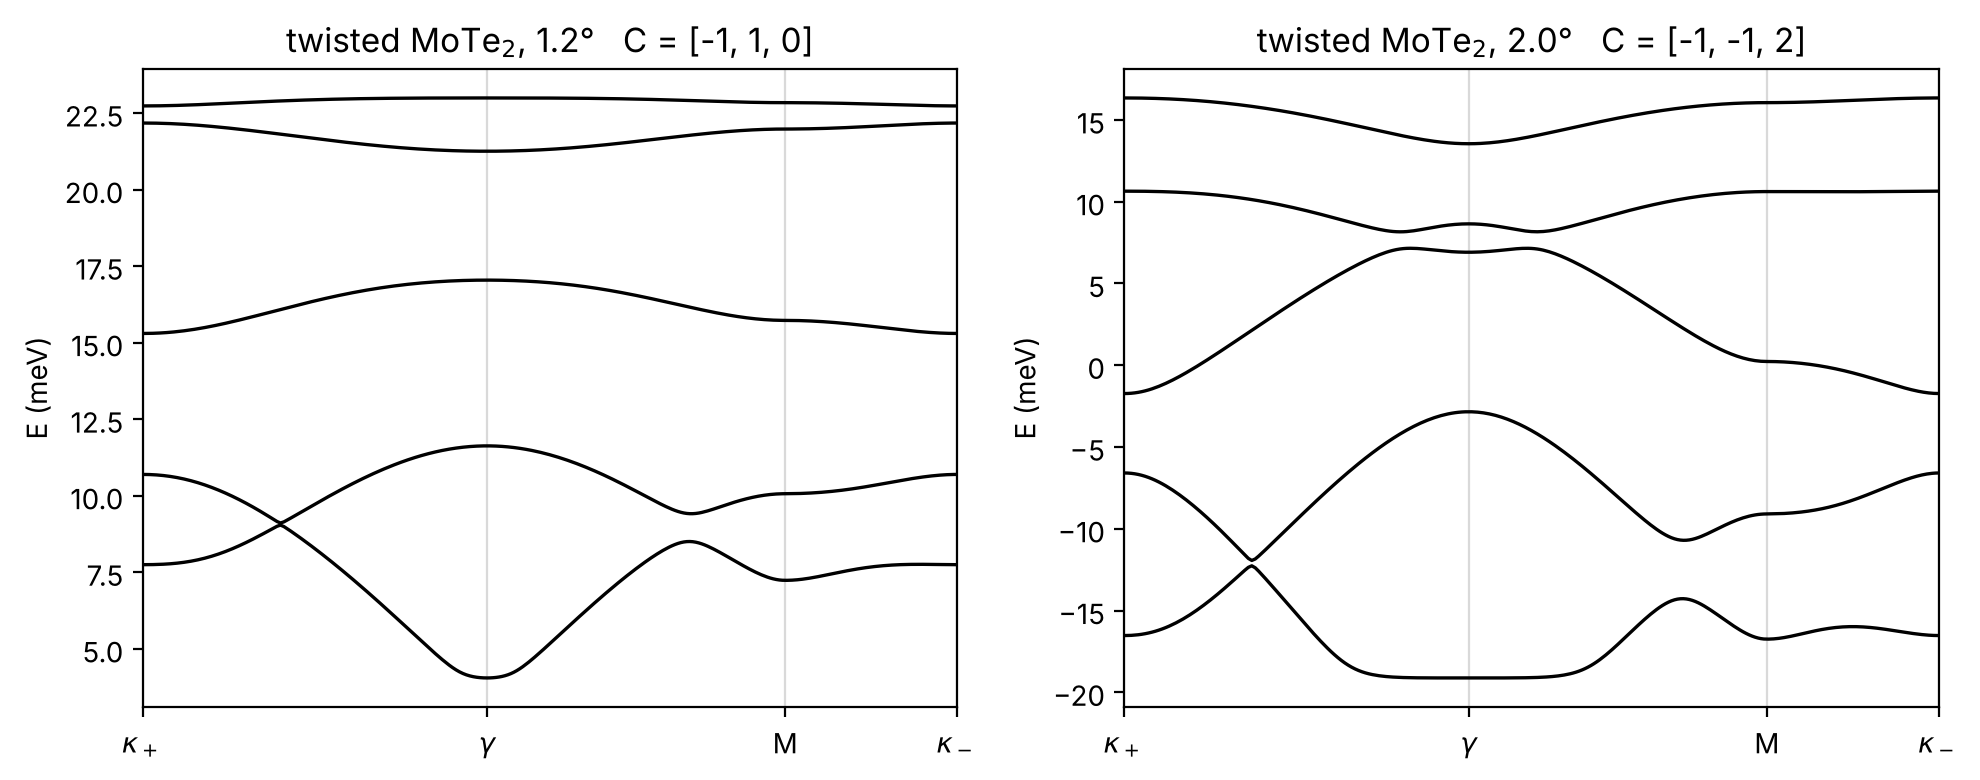

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, th in zip(ax, (1.2, 2.0)):
    m = MD.TMDHomobilayer(theta=th)
    m.plot_bands(nbands=5, ax=a)
    C = m.chern_numbers(3, nk=24)
    a.set_title(f"twisted MoTe$_2$, {th}°   C = {np.round(C).astype(int).tolist()}")
plt.tight_layout()

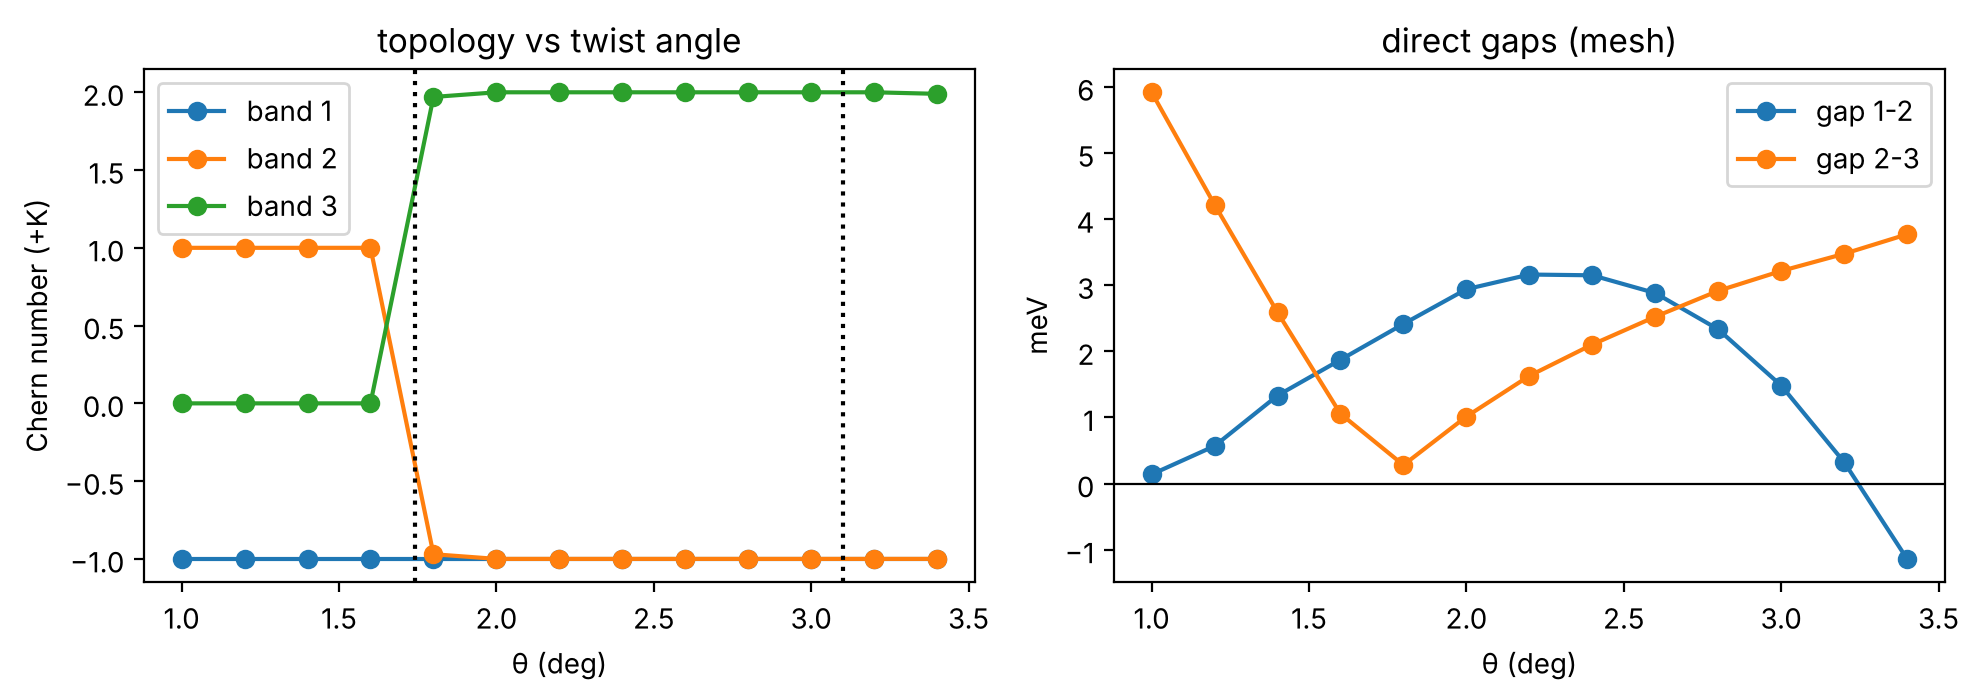

In [6]:
ths = np.linspace(1.0, 3.4, 13)
Cs, gaps = [], []
for th in ths:
    m = MD.TMDHomobilayer(theta=th)
    Cs.append(np.round(m.chern_numbers(3, nk=18), 2)); gaps.append(m.gaps(3, nk=18))
Cs, gaps = np.array(Cs), np.array(gaps)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for i in range(3): ax[0].plot(ths, Cs[:, i], "o-", label=f"band {i+1}")
ax[0].axvline(1.74, ls=":", c="k"); ax[0].axvline(3.1, ls=":", c="k")
ax[0].set_xlabel("θ (deg)"); ax[0].set_ylabel("Chern number (+K)"); ax[0].legend(); ax[0].set_title("topology vs twist angle")
for i in range(2): ax[1].plot(ths, gaps[:, i], "o-", label=f"gap {i+1}-{i+2}")
ax[1].axhline(0, c="k", lw=0.8); ax[1].set_xlabel("θ (deg)"); ax[1].set_ylabel("meV"); ax[1].legend(); ax[1].set_title("direct gaps (mesh)")
plt.tight_layout()

The top band keeps $C=-1$ in the +K valley up to $\theta_2^*\approx3.1^\circ$. Its time-reversal partner in −K has $C=+1$, so a filled top band is a **quantum spin Hall insulator**. This is how the moiré bands realise the Kane-Mele model. The `TMDHomobilayer(Vz=...)` parameter adds a displacement field that eventually trivialises the bands.

Text(0, 0.5, '$k_y$ (1/nm)')

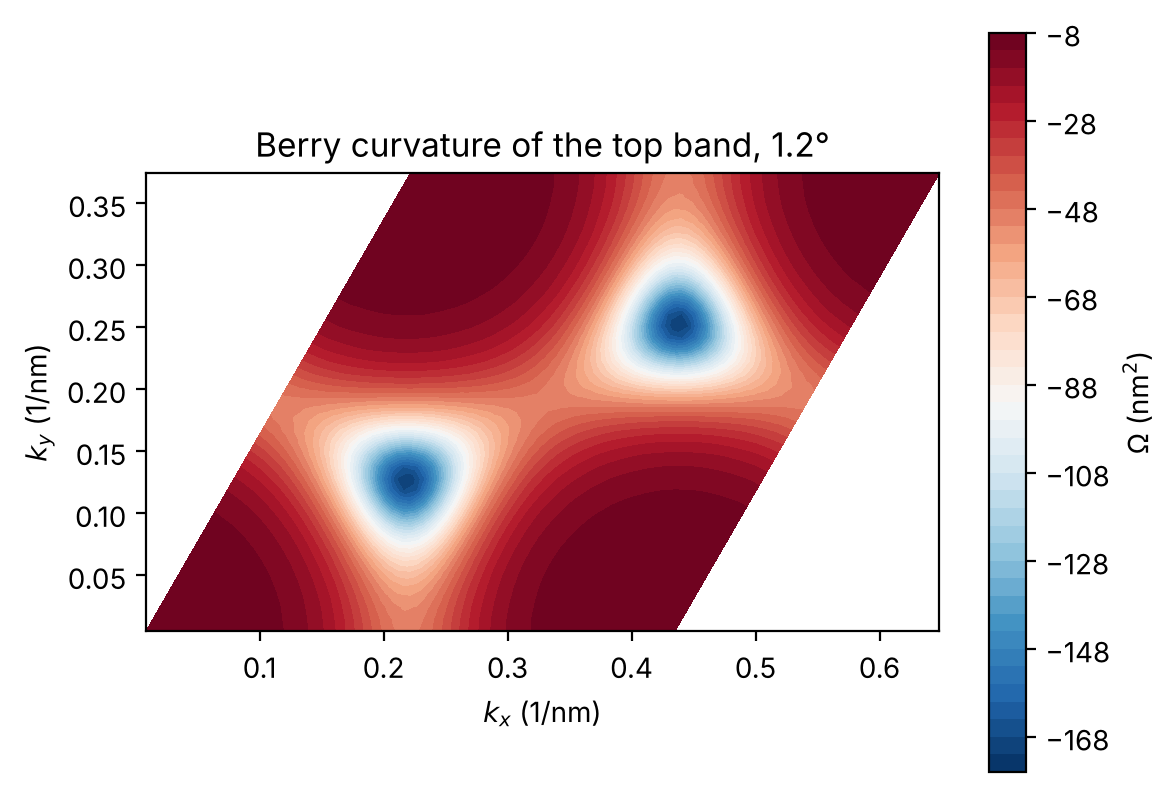

In [7]:
m = MD.TMDHomobilayer(theta=1.2)
k = m.kmesh(40)
Om = m.berry_curvature(k, nbands=1)[:, 0]
plt.tricontourf(k[:, 0], k[:, 1], Om, 40, cmap="RdBu_r"); plt.colorbar(label="Ω (nm$^2$)")
plt.gca().set_aspect("equal"); plt.title("Berry curvature of the top band, 1.2°"); plt.xlabel("$k_x$ (1/nm)"); plt.ylabel("$k_y$ (1/nm)")

## 3 · Rhombohedral (ABC) graphene: chiral decomposition

Near K, ABC $N$-layer graphene has a single pair of bands $E\approx\pm(vk)^N/t_\perp^{N-1}$ with Berry phase $N\pi$ (Min & MacDonald 2008). A layer bias gaps it with valley Chern numbers $\pm N/2$, the origin of the spontaneous quantum Hall states studied by the group.

N = 2: valley Chern K = +0.999, K' = -0.999


N = 3: valley Chern K = +1.500, K' = -1.500


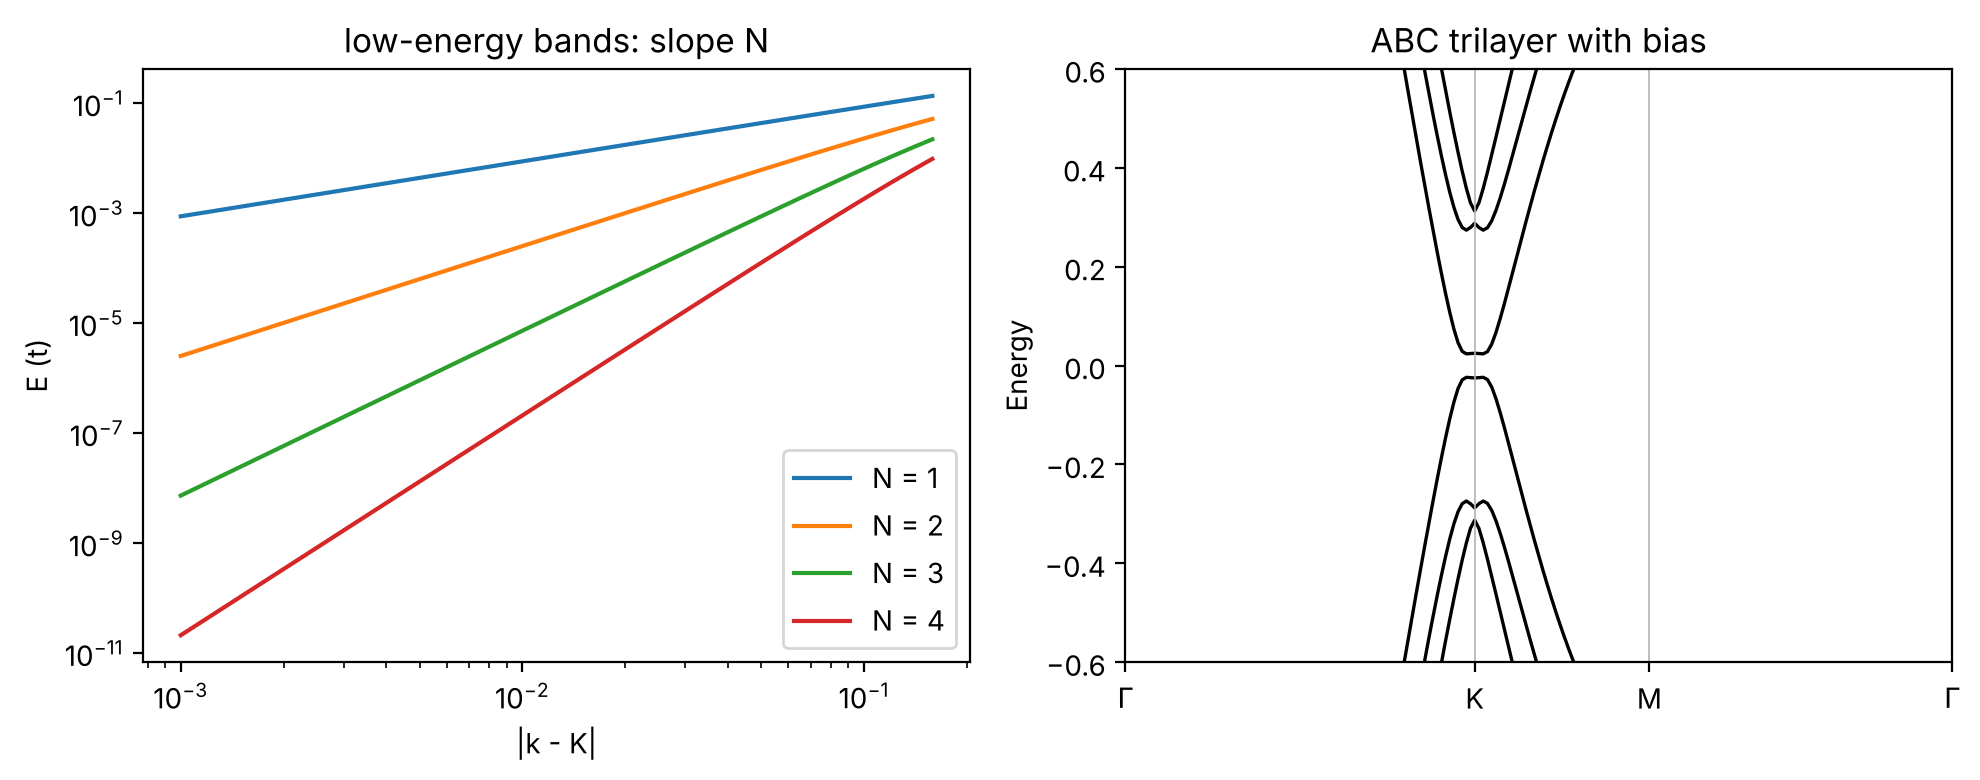

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
dk = np.logspace(-3, -0.8, 40)
for N in (1, 2, 3, 4):
    g = MD.rhombohedral_graphene(N, tperp=0.3)
    B = g.lat.reciprocal[:2, :2]
    kf = np.linalg.solve(B.T, (np.array([2/3, 1/3]) @ B + dk[:, None] * [1, 0]).T).T
    E = g.energies(kf)[:, N]
    ax[0].loglog(dk, E, label=f"N = {N}")
ax[0].set_xlabel("|k - K|"); ax[0].set_ylabel("E (t)"); ax[0].legend(); ax[0].set_title("low-energy bands: slope N")
g = MD.rhombohedral_graphene(3, tperp=0.3, bias=0.05)
hf.plot_bands(g, hf.kpath(g, ["G", "K", "M", "G"], 200), ax=ax[1]); ax[1].set_ylim(-0.6, 0.6); ax[1].set_title("ABC trilayer with bias")
plt.tight_layout()
for N in (2, 3):
    gN = MD.rhombohedral_graphene(N, tperp=0.3, bias=0.02)
    print(f"N = {N}: valley Chern K = {MD.valley_chern(gN, N, [2/3, 1/3]):+.3f}, K' = {MD.valley_chern(gN, N, [1/3, 2/3]):+.3f}")

## 4 · Universal intrinsic spin Hall conductivity

For a Rashba electron gas with both spin-split bands occupied, the intrinsic (Berry-curvature-like) spin Hall conductivity
is $\sigma_{sH}=e/8\pi$, independent of $\alpha$ and of density (Sinova et al. 2004). hopforge reports spin Hall
conductivities in $(\hbar/e)\,e^2/h$ with $s=\sigma/2$, where $e/8\pi = 1/4$.

Text(0.5, 1.0, 'universal plateau once both Rashba bands are occupied')

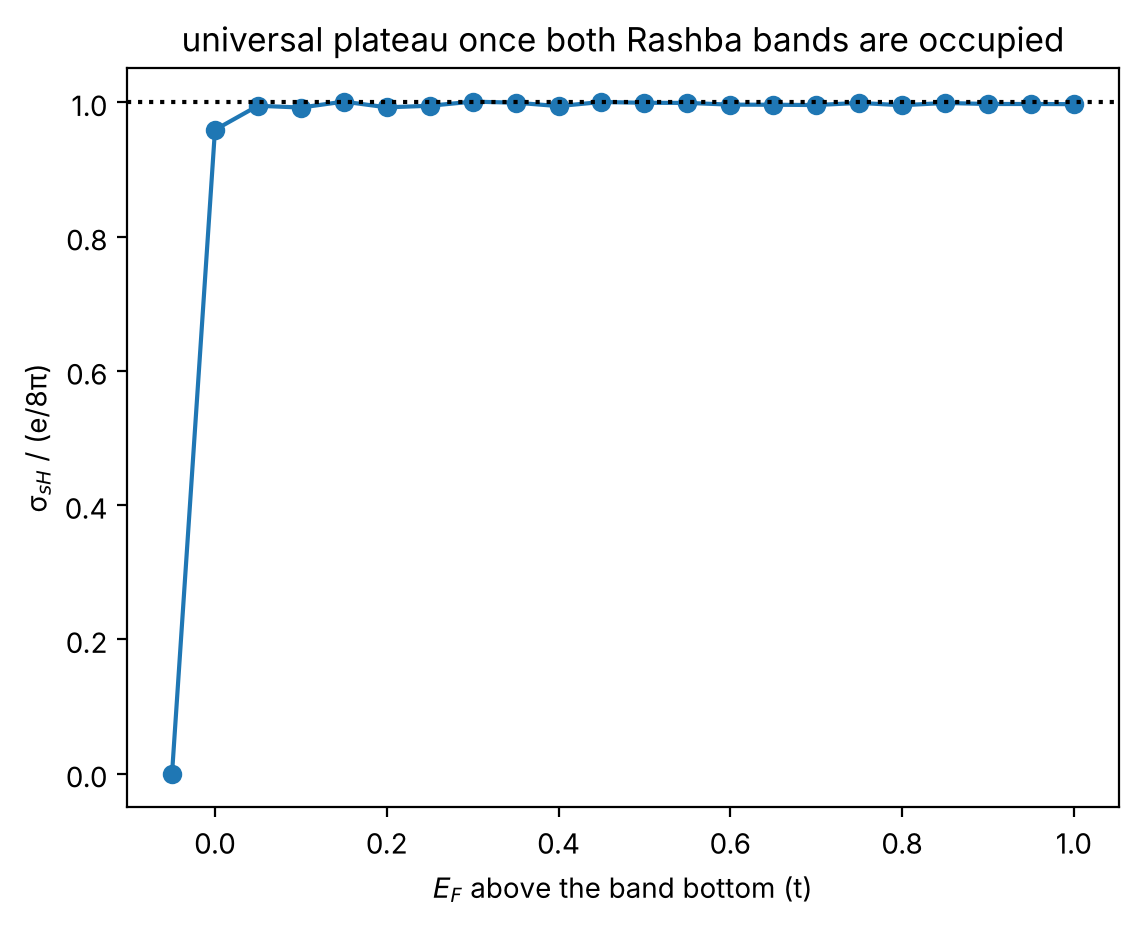

In [9]:
m = MD.rashba_2deg(alpha=0.1)
mus = np.linspace(-4.05, -3.0, 22)
r = hf.spin_hall(m, mu=mus, nk=500, n_jobs=-1)
plt.plot(mus + 4, np.abs(r.sigma) / 0.25, "o-")
plt.axhline(1, c="k", ls=":"); plt.xlabel("$E_F$ above the band bottom (t)"); plt.ylabel("σ$_{sH}$ / (e/8π)")
plt.title("universal plateau once both Rashba bands are occupied")

## 5 · Quantum anomalous Hall effect in graphene
Rashba coupling plus an exchange field opens a bulk gap with Chern number $C=2$ (both valleys contribute).

C = 2.0


Text(0.5, 1.0, 'graphene QAH: plateau at |σ| = 2')

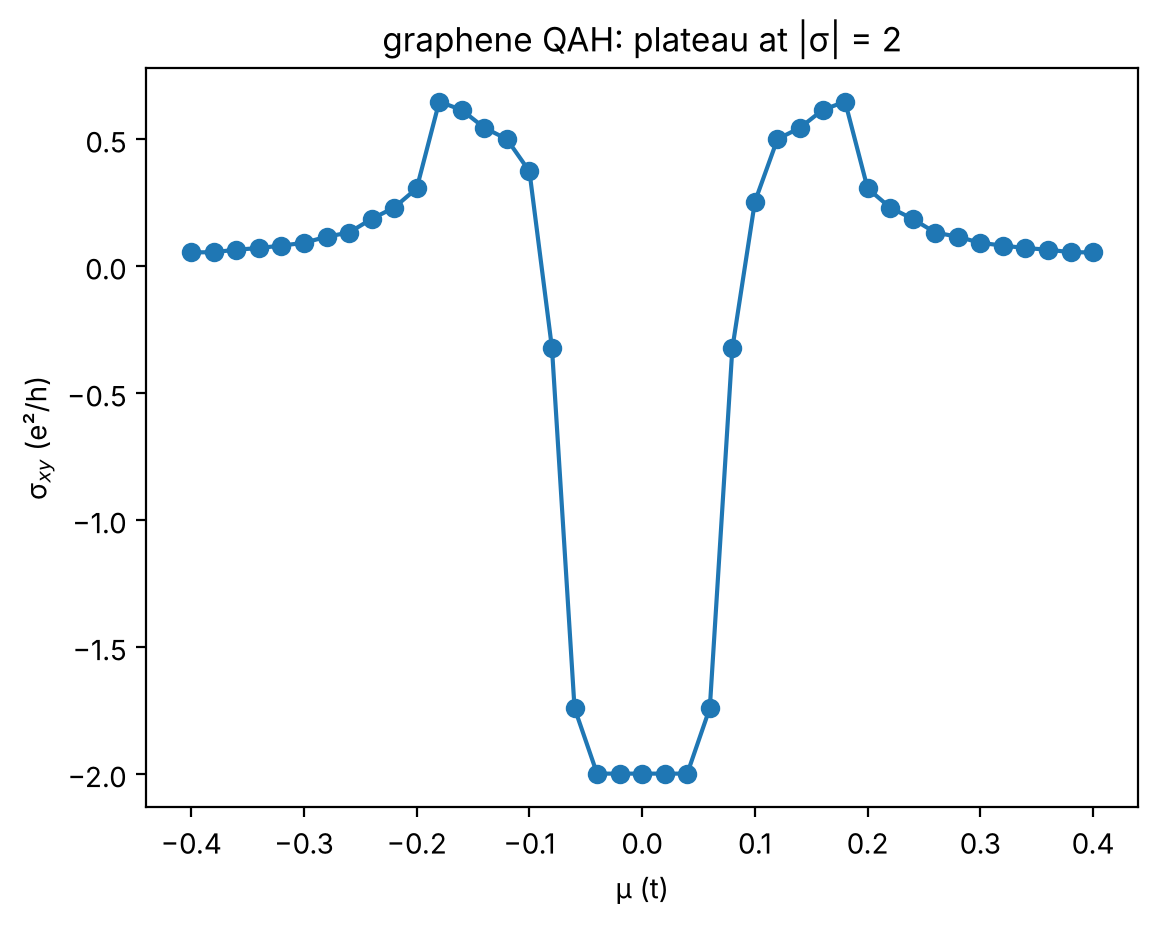

In [10]:
q = MD.graphene_qah(lr=0.05, M=0.1)
print("C =", hf.chern_number(q, occ=2, nk=120))
r = hf.anomalous_hall(q, mu=np.linspace(-0.4, 0.4, 41), nk=150, n_jobs=-1)
plt.plot(r.mu, r.sigma, "o-"); plt.xlabel("μ (t)"); plt.ylabel("σ$_{xy}$ (e²/h)"); plt.title("graphene QAH: plateau at |σ| = 2")

## Summary
* `TMDHeterobilayer` turns a twisted heterobilayer into a generalised triangular Hubbard model with angle-tunable $t$ and $U$. `to_model()` exports it to all hopforge solvers (ED, mean field, phase diagrams).
* `TMDHomobilayer` reproduces the topological bands of twisted MoTe$_2$, including the Chern numbers and both critical angles.
* `rhombohedral_graphene`, `rashba_2deg` and `graphene_qah` are ordinary hopforge models. They work with Kubo, transport, KPM and surface tools.
* Every number above is a benchmark in `hf.benchmarks`.

---
## Quiz 21: MacDonald-group models

Twenty multiple-choice questions on this module. Run the next cell for a clickable
version (needs `ipywidgets`), or use the text version below it and grade yourself with
`quiz.check({1: 'a', 2: 'c', ...})`.

In [11]:
quiz = hf.Quiz(21)
quiz.interactive()

In [12]:
quiz.show()

=== Quiz 21: Allan MacDonald's models: moire TMDs, rhombohedral graphene, spin Hall, QAH ===

Q1. The Bistritzer-MacDonald model describes twisted bilayer graphene in
   (a) Boltzmann theory
   (b) a plane-wave basis on the moire reciprocal lattice
   (c) an atomistic tight-binding supercell only
   (d) DMFT

Q2. In a TMD heterobilayer, holes in the top moire band localise at
   (a) the maxima of the moire potential Delta(r)
   (b) the layer interface only
   (c) random positions
   (d) the minima of Delta(r)

Q3. Why does a TMD heterobilayer give a (nearly) single-band Hubbard model?
   (a) the moire period is atomic
   (b) there is no spin
   (c) large spin-orbit splitting locks spin to valley, leaving one doublet per moire site
   (d) graphene is gapless

Q4. The moire period with twist theta and lattice mismatch delta is
   (a) aM = a0
   (b) aM = a0 / sqrt(theta^2 + delta^2)
   (c) aM = a0 theta
   (d) aM = a0 / delta^2

Q5. In the harmonic approximation the moire well gives
   (a

In [13]:
my_answers = {
    1: '',
    2: '',
    3: '',
    4: '',
    5: '',
    6: '',
    7: '',
    8: '',
    9: '',
    10: '',
    11: '',
    12: '',
    13: '',
    14: '',
    15: '',
    16: '',
    17: '',
    18: '',
    19: '',
    20: '',
}
quiz.check(my_answers)

Q1: (no answer)
Q2: (no answer)
Q3: (no answer)
Q4: (no answer)
Q5: (no answer)
Q6: (no answer)
Q7: (no answer)
Q8: (no answer)
Q9: (no answer)
Q10: (no answer)
Q11: (no answer)
Q12: (no answer)
Q13: (no answer)
Q14: (no answer)
Q15: (no answer)
Q16: (no answer)
Q17: (no answer)
Q18: (no answer)
Q19: (no answer)
Q20: (no answer)

Score: 0 / 20


0